# Cerro Alegre - TreeFormer

## 1. Preparación y configuración

## 1. Instalación

In [26]:
#%pip install deepforest

In [ ]:
import ast
from pathlib import Path
import torch
from skimage.feature import peak_local_max
import deepforest.utilities as utilities

# Ajustar esta ruta a la unidad de Google Drive para escritorio, si corresponde.
BASE_DIR = Path(r"G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega")

if not hasattr(utilities, "density_to_points"):
    ruta = BASE_DIR / "utilities.py"
    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta density_to_points en DeepForest y no se encontró {ruta}. "
            "Verificá BASE_DIR o usá tu instalación local original de DeepForest."
        )
    codigo = ruta.read_text(encoding="utf-8")
    arbol = ast.parse(codigo)
    funcion = next((n for n in arbol.body if isinstance(n, ast.FunctionDef)
                    and n.name == "density_to_points"), None)
    if funcion is None:
        raise ValueError(f"No se encontró density_to_points en {ruta}")
    codigo_funcion = ast.get_source_segment(codigo, funcion)
    utilities.__dict__["torch"] = torch
    utilities.__dict__["peak_local_max"] = peak_local_max
    exec(compile(codigo_funcion, str(ruta), "exec"), utilities.__dict__)
    print("density_to_points incorporada desde utilities.py")
else:
    print("density_to_points ya disponible en DeepForest")

density_to_points ya disponible en DeepForest


In [28]:

import importlib
importlib.invalidate_caches()

from deepforest.models.treeformer import TreeFormerModel
from deepforest.models.treeformer_decoder import Regression
from deepforest.losses.ot_loss import OT_Loss
from deepforest.utilities import density_to_points

print("TreeFormerModel: OK")
print("Regression: OK")
print("OT_Loss: OK")
print("density_to_points: OK")


TreeFormerModel: OK
Regression: OK
OT_Loss: OK
density_to_points: OK


### 1.2 Importaciones y versiones

In [29]:
import math
import time
import importlib.metadata as md
from collections import defaultdict

import numpy as np
import pandas as pd
import scipy
from scipy.spatial import cKDTree

import geopandas as gpd
import rasterio
from rasterio.windows import Window
from shapely.geometry import Point

import matplotlib.pyplot as plt

import torch
from tqdm.auto import tqdm

from deepforest.models.treeformer import TreeFormerModel

packages = [
    "deepforest", "torch", "torchvision", "numpy", "scipy",
    "pandas", "geopandas", "rasterio", "transformers",
    "huggingface-hub", "safetensors"
]

for p in packages:
    try:
        print(f"{p:18s}: {md.version(p)}")
    except Exception:
        print(f"{p:18s}: no disponible como metadata")

print("\nImports completos")

deepforest        : 2.1.0
torch             : 2.14.0
torchvision       : 0.29.0
numpy             : 2.4.6
scipy             : 1.17.1
pandas            : 3.0.5
geopandas         : 1.1.4
rasterio          : 1.4.4
transformers      : 5.12.1
huggingface-hub   : 1.29.0
safetensors       : 0.5.3

Imports completos


### 1.3 Rutas y parámetros

In [ ]:
DATOS = BASE_DIR / "datos"
RASTER_PATH = DATOS / "Cerro_Alegre_Censo_Clip_uint8_global.tif"
MASK_PATH = DATOS / "Cerro_Alegre_mascara_valida.tif"
CENSUS_PATH = DATOS / "Censo_CerroAlegre_parcelas_12-15-16.shp"
RESULTS_DIR = BASE_DIR / "resultados" / "treeformer_uv"

MODEL_ID = "weecology/deepforest-tree-point"
PATCH_SIZE = 896
PATCH_OVERLAP = 0.20
STRIDE = int(round(PATCH_SIZE * (1 - PATCH_OVERLAP)))
SCORE_THRESHOLD = 0.10
SCORE_INTEGRATION_RADIUS = 2
MERGE_RADIUS_M = 1.0
MATCH_RADIUS_M = 2.0
MATCH_RADII_M = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
MIN_VALID_FRACTION = 0.01

for p in (RASTER_PATH, MASK_PATH, CENSUS_PATH):
    if not p.is_file():
        raise FileNotFoundError(f"No existe: {p}. Revisá BASE_DIR y la unidad de Drive.")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Resultados:", RESULTS_DIR)

Resultados: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv


### 1.4 Verificar insumos

In [31]:
#Comprobar raster, máscara y censo.
with rasterio.open(RASTER_PATH) as src, rasterio.open(MASK_PATH) as msk:
    print("Raster:", src.width, "x", src.height, "| bandas:", src.count, "| dtype:", src.dtypes)
    print("CRS raster:", src.crs)
    print("Resolución:", src.res)
    print("Máscara:", msk.width, "x", msk.height, "| CRS:", msk.crs)

    if src.count < 3:
        raise ValueError("El raster debe tener al menos 3 bandas RGB.")
    if (src.width, src.height) != (msk.width, msk.height):
        raise ValueError("Raster y máscara tienen dimensiones distintas.")
    if src.crs != msk.crs:
        raise ValueError("Raster y máscara tienen CRS distintos.")
    if src.transform != msk.transform:
        raise ValueError("Raster y máscara tienen transforms distintos.")

    raster_crs = src.crs
    raster_transform = src.transform
    raster_width = src.width
    raster_height = src.height
    pixel_size_m = float((abs(src.res[0]) + abs(src.res[1])) / 2)

census = gpd.read_file(CENSUS_PATH)

if census.crs is None:
    raise ValueError("El shapefile de censo no tiene CRS definido.")

if census.crs != raster_crs:
    census = census.to_crs(raster_crs)

if not census.geometry.geom_type.isin(["Point"]).all():
    print("ADVERTENCIA: hay geometrías no puntuales; se usarán centroides.")
    census = census.copy()
    census["geometry"] = census.geometry.centroid

print("Censo total:", len(census))
print("Tamaño de píxel aproximado:", round(pixel_size_m, 4), "m")

Raster: 2098 x 6373 | bandas: 3 | dtype: ('uint8', 'uint8', 'uint8')
CRS raster: EPSG:32721
Resolución: (0.19440213111415683, 0.1944156425394072)
Máscara: 2098 x 6373 | CRS: EPSG:32721
Censo total: 2917
Tamaño de píxel aproximado: 0.1944 m


### 1.5 Filtrar censo evaluable

In [32]:
#Seleccionar puntos dentro de la máscara válida; reutilizarlos en toda la evaluación.
with rasterio.open(MASK_PATH) as msk:
    mask_arr = msk.read(1)

def points_inside_valid_mask(gdf, transform, mask):
    inv = ~transform
    keep = []
    h, w = mask.shape

    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            keep.append(False)
            continue

        col_f, row_f = inv * (geom.x, geom.y)
        row = int(math.floor(row_f))
        col = int(math.floor(col_f))

        inside = (0 <= row < h) and (0 <= col < w)
        keep.append(bool(inside and mask[row, col] > 0))

    return np.asarray(keep, dtype=bool)

census_valid_flag = points_inside_valid_mask(census, raster_transform, mask_arr)
census_eval = census.loc[census_valid_flag].copy().reset_index(drop=True)

print("Censo total:", len(census))
print("Censo evaluable:", len(census_eval))
print("Excluidos por máscara/NoData:", len(census) - len(census_eval))

Censo total: 2917
Censo evaluable: 2683
Excluidos por máscara/NoData: 234


### 1.6 Cargar modelo

In [33]:
#Seleccionar dispositivo y cargar TreeFormer.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

t0 = time.time()

model = TreeFormerModel.from_pretrained(
    MODEL_ID,
    score_thresh=SCORE_THRESHOLD,
    score_integration_radius=SCORE_INTEGRATION_RADIUS,
)

model = model.to(DEVICE)
model.eval()

TreeFormerModel(
  (backbone): PvtV2Model(
    (encoder): PvtV2Encoder(
      (layers): ModuleList(
        (0): PvtV2EncoderLayer(
          (patch_embedding): PvtV2OverlapPatchEmbeddings(
            (proj): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(3, 3))
            (layer_norm): LayerNorm((64,), eps=1e-06, elementwise_affine=True, bias=True)
          )
          (blocks): ModuleList(
            (0-2): 3 x PvtV2BlockLayer(
              (layer_norm_1): LayerNorm((64,), eps=1e-06, elementwise_affine=True, bias=True)
              (attention): PvtV2SelfAttention(
                (query): Linear(in_features=64, out_features=64, bias=True)
                (key): Linear(in_features=64, out_features=64, bias=True)
                (value): Linear(in_features=64, out_features=64, bias=True)
                (attn_drop): Dropout(p=0.0, inplace=False)
                (proj): Linear(in_features=64, out_features=64, bias=True)
                (proj_drop): Dropout(p=0.0, inplac

## 2. Prueba inicial de una tesela

### 2.1 Funciones de lectura y teselado

In [34]:
# Definir ventanas y preparar los datos para inferencia.
def axis_offsets(length, patch_size, stride):
    if length <= patch_size:
        return [0]

    offsets = list(range(0, length - patch_size + 1, stride))
    last = length - patch_size
    if offsets[-1] != last:
        offsets.append(last)

    return sorted(set(offsets))

ROW_OFFSETS = axis_offsets(raster_height, PATCH_SIZE, STRIDE)
COL_OFFSETS = axis_offsets(raster_width, PATCH_SIZE, STRIDE)

windows = [
    Window(col_off=c, row_off=r, width=PATCH_SIZE, height=PATCH_SIZE)
    for r in ROW_OFFSETS
    for c in COL_OFFSETS
]

print("Teselas geométricas:", len(windows))
print("Filas:", len(ROW_OFFSETS), "| Columnas:", len(COL_OFFSETS))
print("Stride:", STRIDE, "px | overlap:", PATCH_OVERLAP)

def read_rgb_window(src, window):
    # Devuelve tensor float32 CxHxW en [0,1].
    # TreeFormer realiza internamente la normalización del backbone.
    arr = src.read(
        indexes=[1, 2, 3],
        window=window,
        boundless=True,
        fill_value=0,
        out_shape=(3, PATCH_SIZE, PATCH_SIZE),
    )

    arr = arr.astype(np.float32)

    if np.nanmax(arr) > 1.5:
        arr = arr / 255.0

    arr = np.clip(arr, 0.0, 1.0)
    return torch.from_numpy(arr)

def valid_fraction_for_window(msk, window):
    arr = msk.read(
        1,
        window=window,
        boundless=True,
        fill_value=0,
        out_shape=(PATCH_SIZE, PATCH_SIZE),
    )
    return float(np.mean(arr > 0))

Teselas geométricas: 27
Filas: 9 | Columnas: 3
Stride: 717 px | overlap: 0.2


### 2.2 Inferencia de prueba

In [35]:
#Verificar que se generan detecciones reales.
test_window = None
test_valid_fraction = None

with rasterio.open(MASK_PATH) as msk:
    for w in windows:
        frac = valid_fraction_for_window(msk, w)
        if frac >= MIN_VALID_FRACTION:
            test_window = w
            test_valid_fraction = frac
            break

if test_window is None:
    raise RuntimeError("No se encontró ninguna tesela con píxeles válidos.")

with rasterio.open(RASTER_PATH) as src:
    test_tensor = read_rgb_window(src, test_window)

print("Ventana de prueba:", test_window)
print("Fracción válida:", round(test_valid_fraction, 3))
print(
    "Tensor:", tuple(test_tensor.shape), test_tensor.dtype,
    "| min:", float(test_tensor.min()),
    "| max:", float(test_tensor.max())
)

t0 = time.time()

with torch.inference_mode():
    test_output = model([test_tensor.to(DEVICE)])

elapsed = time.time() - t0

if not isinstance(test_output, (list, tuple)) or len(test_output) != 1:
    raise RuntimeError(
        f"Salida inesperada de TreeFormer: tipo={type(test_output)}"
    )

test_pred = test_output[0]

required_keys = {"points", "scores", "labels"}
missing = required_keys.difference(test_pred.keys())

if missing:
    raise RuntimeError(
        f"Faltan claves en la salida: {missing}. "
        f"Claves recibidas: {list(test_pred.keys())}"
    )

points_test = test_pred["points"].detach().cpu().numpy()
scores_test = test_pred["scores"].detach().cpu().numpy()

if points_test.ndim != 2:
    raise RuntimeError(f"Forma inesperada de points: {points_test.shape}")

if len(points_test) > 0 and points_test.shape[1] != 2:
    raise RuntimeError(f"Forma inesperada de points: {points_test.shape}")

if len(points_test) != len(scores_test):
    raise RuntimeError("Cantidad de puntos y scores no coincide.")

print(f"Inferencia de prueba correcta en {elapsed:.1f} s")
print("Puntos detectados en la tesela:", len(points_test))

if len(scores_test):
    print(
        "Score min/medio/max:",
        round(float(scores_test.min()), 3),
        round(float(scores_test.mean()), 3),
        round(float(scores_test.max()), 3),
    )

Ventana de prueba: Window(col_off=0, row_off=0, width=896, height=896)
Fracción válida: 0.553
Tensor: (3, 896, 896) torch.float32 | min: 0.0 | max: 1.0
Inferencia de prueba correcta en 12.2 s
Puntos detectados en la tesela: 156
Score min/medio/max: 0.119 0.501 0.743


## 3. Inferencia y predicciones georreferenciadas

### 3.1 Inferencia completa

In [36]:
# Ejecutar TreeFormer sobre todas las teselas seleccionadas.
raw_predictions = []
processed_windows = 0
skipped_windows = 0

with rasterio.open(RASTER_PATH) as src, rasterio.open(MASK_PATH) as msk:
    valid_windows = []

    for idx, w in enumerate(windows):
        frac = valid_fraction_for_window(msk, w)

        if frac >= MIN_VALID_FRACTION:
            valid_windows.append((idx, w, frac))
        else:
            skipped_windows += 1

    print("Teselas a procesar:", len(valid_windows))
    print("Teselas omitidas:", skipped_windows)

    start_all = time.time()

    for tile_id, w, valid_frac in tqdm(valid_windows, desc="TreeFormer"):
        tile_tensor = read_rgb_window(src, w)

        with torch.inference_mode():
            out = model([tile_tensor.to(DEVICE)])[0]

        pts = out["points"].detach().cpu().numpy()
        scores = out["scores"].detach().cpu().numpy()
        labels = out["labels"].detach().cpu().numpy()

        if len(pts) == 0:
            processed_windows += 1
            continue

        global_cols = pts[:, 0] + float(w.col_off)
        global_rows = pts[:, 1] + float(w.row_off)

        xs, ys = rasterio.transform.xy(
            src.transform,
            global_rows,
            global_cols,
            offset="center",
        )

        for local_i, (px, py, x, y, score, label) in enumerate(
            zip(pts[:, 0], pts[:, 1], xs, ys, scores, labels)
        ):
            raw_predictions.append({
                "tile_id": int(tile_id),
                "local_id": int(local_i),
                "pixel_x": float(px),
                "pixel_y": float(py),
                "x": float(x),
                "y": float(y),
                "score": float(score),
                "label": int(label),
                "tile_valid_fraction": float(valid_frac),
            })

        processed_windows += 1

elapsed_all = time.time() - start_all

raw_df = pd.DataFrame(raw_predictions)

print("\nInferencia completa")
print("Teselas procesadas:", processed_windows)
print("Predicciones crudas:", len(raw_df))
print(f"Tiempo total: {elapsed_all / 60:.1f} min")

if len(raw_df) == 0:
    raise RuntimeError(
        "TreeFormer no produjo ninguna predicción. "
        "Revisar raster, escala radiométrica y umbral."
    )

Teselas a procesar: 23
Teselas omitidas: 4


TreeFormer:   0%|          | 0/23 [00:00<?, ?it/s]


Inferencia completa
Teselas procesadas: 23
Predicciones crudas: 3604
Tiempo total: 4.2 min


### 3.2 Filtrar por cobertura válida

In [37]:
# Filtrar predicciones por máscara válida
def xy_is_valid(x, y, transform, mask):
    inv = ~transform
    col_f, row_f = inv * (x, y)
    row = int(math.floor(row_f))
    col = int(math.floor(col_f))

    if row < 0 or col < 0 or row >= mask.shape[0] or col >= mask.shape[1]:
        return False

    return bool(mask[row, col] > 0)

raw_df["inside_valid_mask"] = [
    xy_is_valid(x, y, raster_transform, mask_arr)
    for x, y in zip(raw_df["x"], raw_df["y"])
]

valid_pred_df = raw_df.loc[
    raw_df["inside_valid_mask"]
].copy().reset_index(drop=True)

print("Predicciones crudas:", len(raw_df))
print("Predicciones en máscara válida:", len(valid_pred_df))
print("Excluidas por máscara/NoData:", len(raw_df) - len(valid_pred_df))

Predicciones crudas: 3604
Predicciones en máscara válida: 3417
Excluidas por máscara/NoData: 187


### 3.3 Unir detecciones repetidas

In [38]:
# Resolver duplicados por solapamiento entre teselas
def merge_predictions_by_radius(df, radius_m):
    if len(df) <= 1:
        result = df.copy().reset_index(drop=True)
        result["merge_cluster_size"] = 1
        return result

    coords = df[["x", "y"]].to_numpy(dtype=float)
    tree = cKDTree(coords)
    pairs = tree.query_pairs(r=radius_m)

    parent = np.arange(len(df))
    rank = np.zeros(len(df), dtype=int)

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a

    def union(a, b):
        ra = find(a)
        rb = find(b)

        if ra == rb:
            return

        if rank[ra] < rank[rb]:
            parent[ra] = rb
        elif rank[ra] > rank[rb]:
            parent[rb] = ra
        else:
            parent[rb] = ra
            rank[ra] += 1

    for a, b in pairs:
        union(a, b)

    groups = defaultdict(list)

    for i in range(len(df)):
        groups[find(i)].append(i)

    rows = []

    for inds in groups.values():
        subset = df.iloc[inds]
        best_pos = int(np.argmax(subset["score"].to_numpy()))
        best = subset.iloc[best_pos].copy()
        best["merge_cluster_size"] = len(inds)
        rows.append(best)

    merged = pd.DataFrame(rows).reset_index(drop=True)
    merged = merged.sort_values("score", ascending=False).reset_index(drop=True)

    return merged

pred_df = merge_predictions_by_radius(valid_pred_df, MERGE_RADIUS_M)

print("Antes del merge:", len(valid_pred_df))
print("Después del merge:", len(pred_df))
print("Duplicados removidos:", len(valid_pred_df) - len(pred_df))
print("Radio de merge:", MERGE_RADIUS_M, "m")

Antes del merge: 3417
Después del merge: 2261
Duplicados removidos: 1156
Radio de merge: 1.0 m


### 3.4 Exportar predicciones

In [39]:
import tempfile
import shutil

pred_gdf = gpd.GeoDataFrame(
    pred_df.copy(),
    geometry=gpd.points_from_xy(pred_df["x"], pred_df["y"]),
    crs=raster_crs,
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
gpkg_path = RESULTS_DIR / "treeformer_predicciones.gpkg"
csv_path = RESULTS_DIR / "treeformer_predicciones.csv"

with tempfile.TemporaryDirectory(prefix="treeformer_") as tmp:
    gpkg_local = Path(tmp) / gpkg_path.name
    pred_gdf.to_file(gpkg_local, layer="treeformer_points", driver="GPKG")
    shutil.copy2(gpkg_local, gpkg_path)

pred_df.to_csv(csv_path, index=False)
print("Exportado:", gpkg_path, "y", csv_path, sep="\n")

Exportado:
G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\treeformer_predicciones.gpkg
y
G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\treeformer_predicciones.csv


## 4. Evaluación frente al censo

### 4.1 Correspondencia 1:1

In [40]:
# Calcular TP, FP y FN con los puntos del censo evaluable.

def greedy_point_matching(pred_gdf, truth_gdf, radius_m):
    n_pred = len(pred_gdf)
    n_true = len(truth_gdf)

    if n_pred == 0 or n_true == 0:
        return {
            "tp": 0,
            "fp": n_pred,
            "fn": n_true,
            "precision": 0.0,
            "recall": 0.0,
            "f1": 0.0,
            "matches": pd.DataFrame(
                columns=["pred_idx", "truth_idx", "distance_m"]
            ),
        }

    pred_xy = np.column_stack(
        [pred_gdf.geometry.x, pred_gdf.geometry.y]
    )
    true_xy = np.column_stack(
        [truth_gdf.geometry.x, truth_gdf.geometry.y]
    )

    truth_tree = cKDTree(true_xy)
    candidates = []

    for p_idx, xy in enumerate(pred_xy):
        neighbors = truth_tree.query_ball_point(xy, r=radius_m)

        for t_idx in neighbors:
            distance = float(np.linalg.norm(xy - true_xy[t_idx]))
            candidates.append((distance, p_idx, t_idx))

    candidates.sort(key=lambda z: z[0])

    used_pred = set()
    used_true = set()
    matches = []

    for distance, p_idx, t_idx in candidates:
        if p_idx in used_pred or t_idx in used_true:
            continue

        used_pred.add(p_idx)
        used_true.add(t_idx)
        matches.append((p_idx, t_idx, distance))

    tp = len(matches)
    fp = n_pred - tp
    fn = n_true - tp

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall)
        else 0.0
    )

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "matches": pd.DataFrame(
            matches,
            columns=["pred_idx", "truth_idx", "distance_m"],
        ),
    }

main_metrics = greedy_point_matching(
    pred_gdf,
    census_eval,
    MATCH_RADIUS_M,
)

print(f"Radio de matching: {MATCH_RADIUS_M:.2f} m")
print("TP:", main_metrics["tp"])
print("FP:", main_metrics["fp"])
print("FN:", main_metrics["fn"])
print("Precision:", round(main_metrics["precision"], 3))
print("Recall:", round(main_metrics["recall"], 3))
print("F1:", round(main_metrics["f1"], 3))

count_error_pct = (
    100 * (len(pred_gdf) - len(census_eval)) / len(census_eval)
    if len(census_eval) else float("nan")
)

print("Predicciones finales:", len(pred_gdf))
print("Censo evaluable:", len(census_eval))
print("Error de conteo (%):", round(count_error_pct, 2))

Radio de matching: 2.00 m
TP: 1580
FP: 681
FN: 1103
Precision: 0.699
Recall: 0.589
F1: 0.639
Predicciones finales: 2261
Censo evaluable: 2683
Error de conteo (%): -15.73


### 4.2 Sensibilidad al radio

In [41]:
# Sensibilidad al radio de matching

sensitivity_rows = []

for radius in MATCH_RADII_M:
    metrics = greedy_point_matching(
        pred_gdf,
        census_eval,
        radius,
    )

    sensitivity_rows.append({
        "match_radius_m": radius,
        "TP": metrics["tp"],
        "FP": metrics["fp"],
        "FN": metrics["fn"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"],
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)

display(
    sensitivity_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
    })
)

sensitivity_df.to_csv(
    RESULTS_DIR / "treeformer_sensibilidad_radio_matching.csv",
    index=False,
)

,match_radius_m,TP,FP,FN,Precision,Recall,F1
0,0.500000,143,2118,2540,0.063,0.053,0.058
1,1.000000,501,1760,2182,0.222,0.187,0.203
2,1.500000,1075,1186,1608,0.475,0.401,0.435
3,2.000000,1580,681,1103,0.699,0.589,0.639
4,2.500000,1875,386,808,0.829,0.699,0.758
5,3.000000,1987,274,696,0.879,0.741,0.804


### 4.3 Distancias entre árboles

Vecino más cercano del censo (m)
mínimo: 1.86
p05: 3.99
mediana: 6.2
media: 6.21


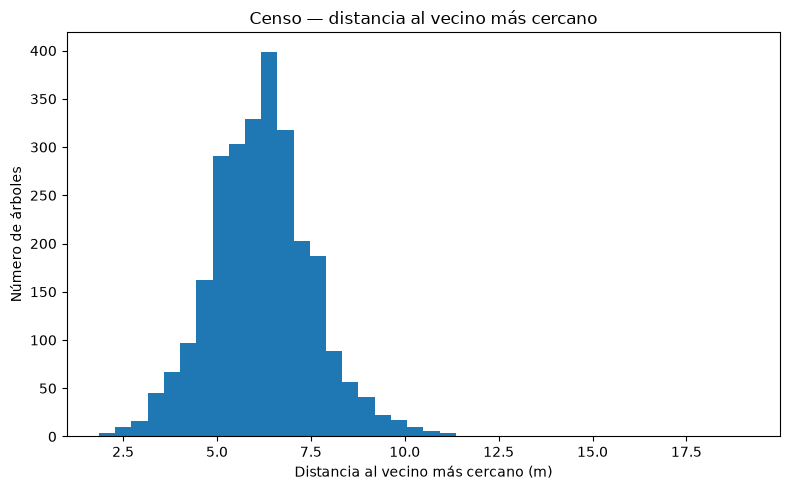

In [42]:
# Distancia al vecino más cercano en el censo

truth_xy = np.column_stack(
    [census_eval.geometry.x, census_eval.geometry.y]
)

truth_tree = cKDTree(truth_xy)
dists, _ = truth_tree.query(truth_xy, k=2)
nn_dist = dists[:, 1]

print("Vecino más cercano del censo (m)")
print("mínimo:", round(float(np.min(nn_dist)), 2))
print("p05:", round(float(np.percentile(nn_dist, 5)), 2))
print("mediana:", round(float(np.median(nn_dist)), 2))
print("media:", round(float(np.mean(nn_dist)), 2))

plt.figure(figsize=(8, 5))
plt.hist(nn_dist, bins=40)
plt.xlabel("Distancia al vecino más cercano (m)")
plt.ylabel("Número de árboles")
plt.title("Censo — distancia al vecino más cercano")
plt.tight_layout()
plt.show()

### 4.4 Distribución de confianza

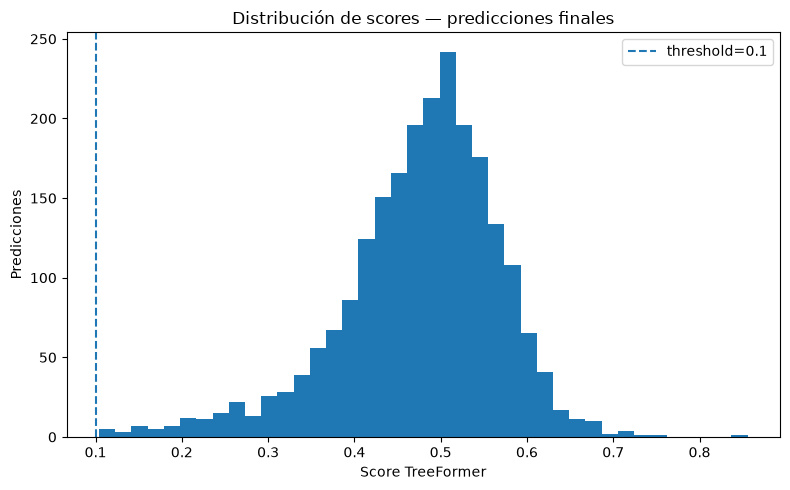

In [43]:
# Histograma de scores

plt.figure(figsize=(8, 5))
plt.hist(pred_gdf["score"], bins=40)
plt.axvline(
    SCORE_THRESHOLD,
    linestyle="--",
    label=f"threshold={SCORE_THRESHOLD}",
)
plt.xlabel("Score TreeFormer")
plt.ylabel("Predicciones")
plt.title("Distribución de scores — predicciones finales")
plt.legend()
plt.tight_layout()
plt.show()

### 4.5 Control visual

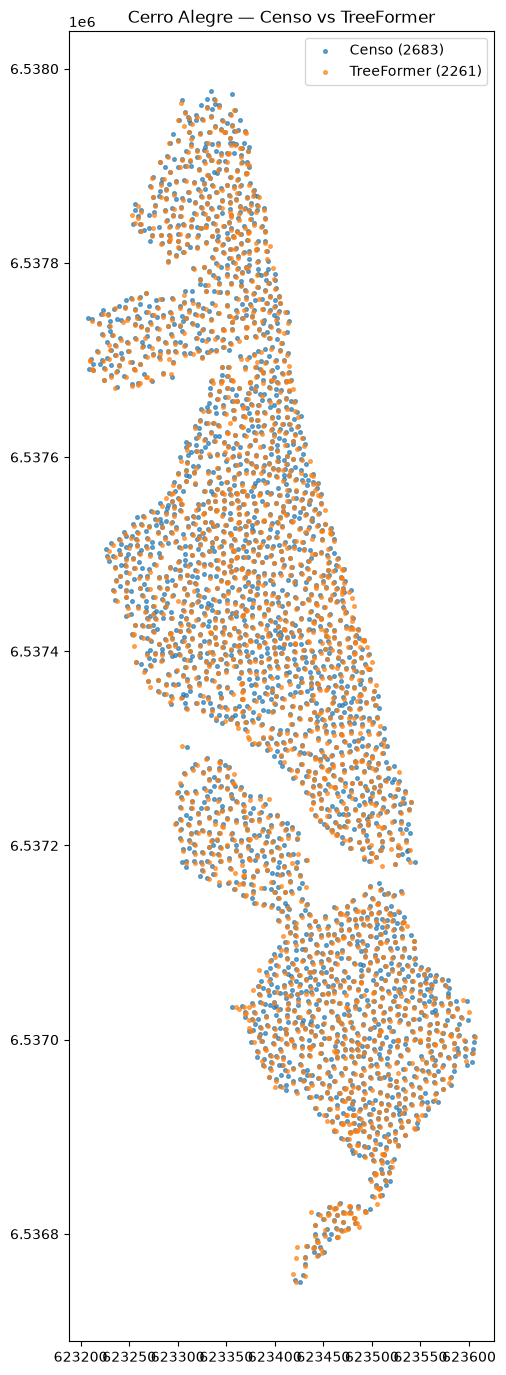

Mapa guardado: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\treeformer_censo_vs_predicciones.png


In [44]:
# Mapa de control visual

fig, ax = plt.subplots(figsize=(10, 14))

census_eval.plot(
    ax=ax,
    markersize=7,
    alpha=0.65,
    label=f"Censo ({len(census_eval)})",
)

pred_gdf.plot(
    ax=ax,
    markersize=7,
    alpha=0.65,
    label=f"TreeFormer ({len(pred_gdf)})",
)

ax.set_title("Cerro Alegre — Censo vs TreeFormer")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()

map_path = RESULTS_DIR / "treeformer_censo_vs_predicciones.png"
plt.savefig(map_path, dpi=200, bbox_inches="tight")
plt.show()

print("Mapa guardado:", map_path)

### 4.6 Exportar evaluación base

In [45]:
# Guardar coincidencias y métricas.

matches = main_metrics["matches"].copy()

if len(matches):
    matches["pred_score"] = matches["pred_idx"].map(
        pred_gdf["score"]
    )

    matches.to_csv(
        RESULTS_DIR / f"treeformer_matches_{MATCH_RADIUS_M:.1f}m.csv",
        index=False,
    )

summary = pd.DataFrame([{
    "model": MODEL_ID,
    "patch_size_px": PATCH_SIZE,
    "patch_overlap": PATCH_OVERLAP,
    "score_threshold": SCORE_THRESHOLD,
    "score_integration_radius": SCORE_INTEGRATION_RADIUS,
    "merge_radius_m": MERGE_RADIUS_M,
    "match_radius_m": MATCH_RADIUS_M,
    "census_total": len(census),
    "census_evaluable": len(census_eval),
    "predictions_raw": len(raw_df),
    "predictions_valid_mask": len(valid_pred_df),
    "predictions_final": len(pred_gdf),
    "TP": main_metrics["tp"],
    "FP": main_metrics["fp"],
    "FN": main_metrics["fn"],
    "Precision": main_metrics["precision"],
    "Recall": main_metrics["recall"],
    "F1": main_metrics["f1"],
    "count_error_pct": count_error_pct,
    "device": str(DEVICE),
}])

summary_path = RESULTS_DIR / "treeformer_resumen.csv"
summary.to_csv(summary_path, index=False)

display(summary.T)
print("Resumen:", summary_path)

,0
model,weecology/deepforest-tree-point
patch_size_px,896
patch_overlap,0.2
score_threshold,0.1
score_integration_radius,2
merge_radius_m,1.0
match_radius_m,2.0
census_total,2917
census_evaluable,2683
predictions_raw,3604


Resumen: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\treeformer_resumen.csv


## 5. Optimización de parámetros

### 5.1 Configuración del ajuste

In [46]:
# Configuración del tuning
TUNING_DIR = RESULTS_DIR / "tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

# Radio fijo para seleccionar parámetros.
TUNING_MATCH_RADIUS_M = 2.0

# Valores a probar.
SCORE_VALUES = [0.05, 0.10, 0.15, 0.20, 0.25]
PATCH_VALUES = [512, 640, 768, 896, 1024]
OVERLAP_VALUES = [0.10, 0.20, 0.30]
INTEGRATION_RADIUS_VALUES = [1, 2, 3]
MERGE_VALUES_M = [0.50, 0.75, 1.00, 1.25]

# Para seleccionar automáticamente el mejor resultado.
PRIMARY_METRIC = "F1"

print("Directorio de tuning:", TUNING_DIR)
print("Radio fijo de matching:", TUNING_MATCH_RADIUS_M, "m")
print("Métrica principal:", PRIMARY_METRIC)

Directorio de tuning: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\tuning
Radio fijo de matching: 2.0 m
Métrica principal: F1


### 5.2 Funciones de evaluación de configuraciones

In [47]:
# Funciones generales para ejecutar una configuración TreeFormer
def make_windows(width, height, patch_size, overlap):
    stride = int(round(patch_size * (1.0 - overlap)))
    if stride <= 0:
        raise ValueError("El overlap debe ser menor que 1.")

    rows = axis_offsets(height, patch_size, stride)
    cols = axis_offsets(width, patch_size, stride)

    ws = [
        Window(col_off=c, row_off=r, width=patch_size, height=patch_size)
        for r in rows
        for c in cols
    ]
    return ws, stride


def read_rgb_window_variable(src, window, patch_size):
    arr = src.read(
        indexes=[1, 2, 3],
        window=window,
        boundless=True,
        fill_value=0,
        out_shape=(3, patch_size, patch_size),
    ).astype(np.float32)

    if np.nanmax(arr) > 1.5:
        arr /= 255.0

    arr = np.clip(arr, 0.0, 1.0)
    return torch.from_numpy(arr)


def valid_fraction_variable(msk, window, patch_size):
    arr = msk.read(
        1,
        window=window,
        boundless=True,
        fill_value=0,
        out_shape=(patch_size, patch_size),
    )
    return float(np.mean(arr > 0))


def run_treeformer_config(
    patch_size,
    overlap,
    score_threshold,
    integration_radius,
    show_progress=True,
):
    """Ejecuta TreeFormer para UNA configuración y devuelve predicciones crudas.

    No hace merge: el merge se aplica después para poder estudiar distintos
    radios sin repetir la inferencia.
    """

    # Cada configuración carga el checkpoint con los parámetros de postprocesamiento correspondientes.
    local_model = TreeFormerModel.from_pretrained(
        MODEL_ID,
        score_thresh=float(score_threshold),
        score_integration_radius=int(integration_radius),
    )
    local_model = local_model.to(DEVICE)
    local_model.eval()

    ws, stride = make_windows(
        raster_width, raster_height, patch_size, overlap
    )

    predictions = []
    valid_windows = []

    with rasterio.open(MASK_PATH) as msk:
        for tile_id, w in enumerate(ws):
            frac = valid_fraction_variable(msk, w, patch_size)
            if frac >= MIN_VALID_FRACTION:
                valid_windows.append((tile_id, w, frac))

    iterator = valid_windows
    if show_progress:
        iterator = tqdm(
            valid_windows,
            desc=(
                f"P{patch_size} O{overlap:.2f} "
                f"S{score_threshold:.2f} I{integration_radius}"
            )
        )

    t0 = time.time()

    with rasterio.open(RASTER_PATH) as src:
        for tile_id, w, valid_frac in iterator:
            tensor = read_rgb_window_variable(src, w, patch_size)

            with torch.inference_mode():
                out = local_model([tensor.to(DEVICE)])[0]

            pts = out["points"].detach().cpu().numpy()
            scores = out["scores"].detach().cpu().numpy()
            labels = out["labels"].detach().cpu().numpy()

            if len(pts) == 0:
                continue

            global_cols = pts[:, 0] + float(w.col_off)
            global_rows = pts[:, 1] + float(w.row_off)

            xs, ys = rasterio.transform.xy(
                src.transform,
                global_rows,
                global_cols,
                offset="center",
            )

            for local_id, (px, py, x, y, score, label) in enumerate(
                zip(pts[:, 0], pts[:, 1], xs, ys, scores, labels)
            ):
                # Se filtra la máscara en el momento para no conservar detecciones fuera del área evaluable.
                if not xy_is_valid(
                    float(x), float(y), raster_transform, mask_arr
                ):
                    continue

                predictions.append({
                    "tile_id": int(tile_id),
                    "local_id": int(local_id),
                    "pixel_x": float(px),
                    "pixel_y": float(py),
                    "x": float(x),
                    "y": float(y),
                    "score": float(score),
                    "label": int(label),
                    "tile_valid_fraction": float(valid_frac),
                })

    elapsed = time.time() - t0

    # Liberar el modelo local antes de la siguiente corrida.
    del local_model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    return pd.DataFrame(predictions), {
        "patch_size": int(patch_size),
        "overlap": float(overlap),
        "score_threshold": float(score_threshold),
        "integration_radius": int(integration_radius),
        "stride": int(stride),
        "n_windows": len(valid_windows),
        "elapsed_min": elapsed / 60.0,
    }


def evaluate_raw_predictions(
    raw_valid_df,
    merge_radius_m,
    match_radius_m=TUNING_MATCH_RADIUS_M,
):
    """Merge + matching 1:1 + métricas para una salida de inferencia."""

    if len(raw_valid_df) == 0:
        empty_gdf = gpd.GeoDataFrame(
            {"x": [], "y": [], "score": []},
            geometry=gpd.GeoSeries([], crs=raster_crs), crs=raster_crs,
        )
        return empty_gdf, {
            "predictions_before_merge": 0,
            "predictions_final": 0,
            "TP": 0,
            "FP": 0,
            "FN": len(census_eval),
            "Precision": 0.0,
            "Recall": 0.0,
            "F1": 0.0,
            "count_error_pct": -100.0,
        }

    merged_df = merge_predictions_by_radius(
        raw_valid_df,
        float(merge_radius_m),
    )

    merged_gdf = gpd.GeoDataFrame(
        merged_df.copy(),
        geometry=gpd.points_from_xy(
            merged_df["x"], merged_df["y"]
        ),
        crs=raster_crs,
    )

    metrics = greedy_point_matching(
        merged_gdf,
        census_eval,
        float(match_radius_m),
    )

    count_error = (
        100.0 * (len(merged_gdf) - len(census_eval)) / len(census_eval)
    )

    result = {
        "predictions_before_merge": len(raw_valid_df),
        "predictions_final": len(merged_gdf),
        "TP": metrics["tp"],
        "FP": metrics["fp"],
        "FN": metrics["fn"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"],
        "count_error_pct": count_error,
    }

    return merged_gdf, result


def choose_best(results_df):
    """Selecciona mayor F1; desempata por menor |error conteo| y mayor recall."""
    if len(results_df) == 0:
        raise RuntimeError("No hay resultados para seleccionar.")

    tmp = results_df.copy()
    tmp["_abs_count_error"] = tmp["count_error_pct"].abs()

    tmp = tmp.sort_values(
        by=["F1", "_abs_count_error", "Recall", "Precision"],
        ascending=[False, True, False, False],
    )

    return tmp.iloc[0].drop(labels=["_abs_count_error"])


def display_tuning_table(df):
    cols = [
        c for c in [
            "stage", "patch_size", "overlap", "score_threshold",
            "integration_radius", "merge_radius_m",
            "predictions_final", "TP", "FP", "FN",
            "Precision", "Recall", "F1",
            "count_error_pct", "elapsed_min"
        ] if c in df.columns
    ]

    formatters = {
        "overlap": "{:.2f}",
        "score_threshold": "{:.2f}",
        "merge_radius_m": "{:.2f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "count_error_pct": "{:.2f}",
        "elapsed_min": "{:.1f}",
    }
    return df[cols].style.format({k: v for k, v in formatters.items() if k in cols})

### 5.3 Ajustar SCORE_THRESHOLD

In [48]:
# Comparar umbrales de confianza.

stage1_rows = []

for score_value in SCORE_VALUES:
    print("\n" + "=" * 70)
    print("SCORE_THRESHOLD =", score_value)

    raw_exp, info = run_treeformer_config(
        patch_size=896,
        overlap=0.20,
        score_threshold=score_value,
        integration_radius=2,
    )

    _, metrics = evaluate_raw_predictions(
        raw_exp,
        merge_radius_m=1.0,
    )

    row = {
        "stage": "score_threshold",
        **info,
        "merge_radius_m": 1.0,
        **metrics,
    }
    stage1_rows.append(row)

    print(
        f"Pred={metrics['predictions_final']} | "
        f"P={metrics['Precision']:.3f} | "
        f"R={metrics['Recall']:.3f} | "
        f"F1={metrics['F1']:.3f} | "
        f"Error conteo={metrics['count_error_pct']:.2f}%"
    )

stage1_df = pd.DataFrame(stage1_rows)
best1 = choose_best(stage1_df)
BEST_SCORE = float(best1["score_threshold"])

display(display_tuning_table(stage1_df))

print("\nMEJOR SCORE_THRESHOLD:", BEST_SCORE)
print("F1:", round(float(best1["F1"]), 3))
print("Error conteo:", round(float(best1["count_error_pct"]), 2), "%")

stage1_df.to_csv(
    TUNING_DIR / "01_tuning_score_threshold.csv",
    index=False,
)


SCORE_THRESHOLD = 0.05


P896 O0.20 S0.05 I2:   0%|          | 0/23 [00:00<?, ?it/s]

Pred=2272 | P=0.695 | R=0.589 | F1=0.638 | Error conteo=-15.32%

SCORE_THRESHOLD = 0.1


P896 O0.20 S0.10 I2:   0%|          | 0/23 [00:00<?, ?it/s]

Pred=2261 | P=0.699 | R=0.589 | F1=0.639 | Error conteo=-15.73%

SCORE_THRESHOLD = 0.15


P896 O0.20 S0.15 I2:   0%|          | 0/23 [00:00<?, ?it/s]

... (3 outputs left out)

P896 O0.20 S0.25 I2:   0%|          | 0/23 [00:00<?, ?it/s]

Pred=2200 | P=0.708 | R=0.581 | F1=0.638 | Error conteo=-18.00%


,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,score_threshold,896,0.20,0.05,2,1.00,2272,1580,692,1103,0.695,0.589,0.638,-15.32,4.0
1,score_threshold,896,0.20,0.10,2,1.00,2261,1580,681,1103,0.699,0.589,0.639,-15.73,4.0
2,score_threshold,896,0.20,0.15,2,1.00,2250,1578,672,1105,0.701,0.588,0.640,-16.14,4.6
3,score_threshold,896,0.20,0.20,2,1.00,2233,1577,656,1106,0.706,0.588,0.642,-16.77,4.4
4,score_threshold,896,0.20,0.25,2,1.00,2200,1558,642,1125,0.708,0.581,0.638,-18.00,4.1



MEJOR SCORE_THRESHOLD: 0.2
F1: 0.642
Error conteo: -16.77 %


### 5.4 Ajustar PATCH_SIZE

In [49]:
# Evaluar distintos tamaños de tesela.

stage2_rows = []

for patch_value in PATCH_VALUES:
    print("\n" + "=" * 70)
    print("PATCH_SIZE =", patch_value)

    raw_exp, info = run_treeformer_config(
        patch_size=patch_value,
        overlap=0.20,
        score_threshold=BEST_SCORE,
        integration_radius=2,
    )

    _, metrics = evaluate_raw_predictions(
        raw_exp,
        merge_radius_m=1.0,
    )

    row = {
        "stage": "patch_size",
        **info,
        "merge_radius_m": 1.0,
        **metrics,
    }
    stage2_rows.append(row)

    print(
        f"Pred={metrics['predictions_final']} | "
        f"P={metrics['Precision']:.3f} | "
        f"R={metrics['Recall']:.3f} | "
        f"F1={metrics['F1']:.3f} | "
        f"Error conteo={metrics['count_error_pct']:.2f}%"
    )

stage2_df = pd.DataFrame(stage2_rows)
best2 = choose_best(stage2_df)
BEST_PATCH = int(best2["patch_size"])

display(display_tuning_table(stage2_df))

print("\nMEJOR PATCH_SIZE:", BEST_PATCH)
print("F1:", round(float(best2["F1"]), 3))
print("Error conteo:", round(float(best2["count_error_pct"]), 2), "%")

stage2_df.to_csv(
    TUNING_DIR / "02_tuning_patch_size.csv",
    index=False,
)


PATCH_SIZE = 512


P512 O0.20 S0.20 I2:   0%|          | 0/57 [00:00<?, ?it/s]

Pred=2342 | P=0.670 | R=0.584 | F1=0.624 | Error conteo=-12.71%

PATCH_SIZE = 640


P640 O0.20 S0.20 I2:   0%|          | 0/41 [00:00<?, ?it/s]

Pred=2364 | P=0.666 | R=0.587 | F1=0.624 | Error conteo=-11.89%

PATCH_SIZE = 768


P768 O0.20 S0.20 I2:   0%|          | 0/34 [00:00<?, ?it/s]

... (3 outputs left out)

P1024 O0.20 S0.20 I2:   0%|          | 0/22 [00:00<?, ?it/s]

Pred=2236 | P=0.720 | R=0.600 | F1=0.654 | Error conteo=-16.66%


,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,patch_size,512,0.20,0.20,2,1.00,2342,1568,774,1115,0.670,0.584,0.624,-12.71,2.8
1,patch_size,640,0.20,0.20,2,1.00,2364,1574,790,1109,0.666,0.587,0.624,-11.89,3.4
2,patch_size,768,0.20,0.20,2,1.00,2279,1576,703,1107,0.692,0.587,0.635,-15.06,4.3
3,patch_size,896,0.20,0.20,2,1.00,2233,1577,656,1106,0.706,0.588,0.642,-16.77,5.1
4,patch_size,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,6.2



MEJOR PATCH_SIZE: 1024
F1: 0.654
Error conteo: -16.66 %


### 5.5 Ajustar PATCH_OVERLAP

In [50]:
# Evaluar distintos solapamientos.

stage3_rows = []

for overlap_value in OVERLAP_VALUES:
    print("\n" + "=" * 70)
    print("PATCH_OVERLAP =", overlap_value)

    raw_exp, info = run_treeformer_config(
        patch_size=BEST_PATCH,
        overlap=overlap_value,
        score_threshold=BEST_SCORE,
        integration_radius=2,
    )

    _, metrics = evaluate_raw_predictions(
        raw_exp,
        merge_radius_m=1.0,
    )

    row = {
        "stage": "patch_overlap",
        **info,
        "merge_radius_m": 1.0,
        **metrics,
    }
    stage3_rows.append(row)

    print(
        f"Pred={metrics['predictions_final']} | "
        f"P={metrics['Precision']:.3f} | "
        f"R={metrics['Recall']:.3f} | "
        f"F1={metrics['F1']:.3f} | "
        f"Error conteo={metrics['count_error_pct']:.2f}%"
    )

stage3_df = pd.DataFrame(stage3_rows)
best3 = choose_best(stage3_df)
BEST_OVERLAP = float(best3["overlap"])

display(display_tuning_table(stage3_df))

print("\nMEJOR PATCH_OVERLAP:", BEST_OVERLAP)
print("F1:", round(float(best3["F1"]), 3))
print("Error conteo:", round(float(best3["count_error_pct"]), 2), "%")

stage3_df.to_csv(
    TUNING_DIR / "03_tuning_patch_overlap.csv",
    index=False,
)


PATCH_OVERLAP = 0.1


P1024 O0.10 S0.20 I2:   0%|          | 0/19 [00:00<?, ?it/s]

Pred=2224 | P=0.715 | R=0.593 | F1=0.648 | Error conteo=-17.11%

PATCH_OVERLAP = 0.2


P1024 O0.20 S0.20 I2:   0%|          | 0/22 [00:00<?, ?it/s]

Pred=2236 | P=0.720 | R=0.600 | F1=0.654 | Error conteo=-16.66%

PATCH_OVERLAP = 0.3


P1024 O0.30 S0.20 I2:   0%|          | 0/25 [00:00<?, ?it/s]

Pred=2302 | P=0.694 | R=0.595 | F1=0.641 | Error conteo=-14.20%


,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,patch_overlap,1024,0.10,0.20,2,1.00,2224,1590,634,1093,0.715,0.593,0.648,-17.11,5.0
1,patch_overlap,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,5.6
2,patch_overlap,1024,0.30,0.20,2,1.00,2302,1597,705,1086,0.694,0.595,0.641,-14.20,6.4



MEJOR PATCH_OVERLAP: 0.2
F1: 0.654
Error conteo: -16.66 %


### 5.6 Ajustar SCORE_INTEGRATION_RADIUS

In [51]:
# Estudiar el radio de integración de propuestas.

stage4_rows = []
stage4_raw = {}

for integration_value in INTEGRATION_RADIUS_VALUES:
    print("\n" + "=" * 70)
    print("SCORE_INTEGRATION_RADIUS =", integration_value)

    raw_exp, info = run_treeformer_config(
        patch_size=BEST_PATCH,
        overlap=BEST_OVERLAP,
        score_threshold=BEST_SCORE,
        integration_radius=integration_value,
    )

    # Guardamos temporalmente las salidas de esta etapa.
    # La mejor será reutilizada para probar MERGE_RADIUS sin inferir otra vez.
    stage4_raw[integration_value] = raw_exp

    _, metrics = evaluate_raw_predictions(
        raw_exp,
        merge_radius_m=1.0,
    )

    row = {
        "stage": "integration_radius",
        **info,
        "merge_radius_m": 1.0,
        **metrics,
    }
    stage4_rows.append(row)

    print(
        f"Pred={metrics['predictions_final']} | "
        f"P={metrics['Precision']:.3f} | "
        f"R={metrics['Recall']:.3f} | "
        f"F1={metrics['F1']:.3f} | "
        f"Error conteo={metrics['count_error_pct']:.2f}%"
    )

stage4_df = pd.DataFrame(stage4_rows)
best4 = choose_best(stage4_df)
BEST_INTEGRATION_RADIUS = int(best4["integration_radius"])

display(display_tuning_table(stage4_df))

print("\nMEJOR SCORE_INTEGRATION_RADIUS:", BEST_INTEGRATION_RADIUS)
print("F1:", round(float(best4["F1"]), 3))
print("Error conteo:", round(float(best4["count_error_pct"]), 2), "%")

stage4_df.to_csv(
    TUNING_DIR / "04_tuning_integration_radius.csv",
    index=False,
)


SCORE_INTEGRATION_RADIUS = 1


P1024 O0.20 S0.20 I1:   0%|          | 0/22 [00:00<?, ?it/s]

Pred=2292 | P=0.707 | R=0.604 | F1=0.651 | Error conteo=-14.57%

SCORE_INTEGRATION_RADIUS = 2


P1024 O0.20 S0.20 I2:   0%|          | 0/22 [00:00<?, ?it/s]

Pred=2236 | P=0.720 | R=0.600 | F1=0.654 | Error conteo=-16.66%

SCORE_INTEGRATION_RADIUS = 3


P1024 O0.20 S0.20 I3:   0%|          | 0/22 [00:00<?, ?it/s]

Pred=2186 | P=0.723 | R=0.589 | F1=0.649 | Error conteo=-18.52%


,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,integration_radius,1024,0.20,0.20,1,1.00,2292,1620,672,1063,0.707,0.604,0.651,-14.57,5.4
1,integration_radius,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,5.3
2,integration_radius,1024,0.20,0.20,3,1.00,2186,1581,605,1102,0.723,0.589,0.649,-18.52,5.3



MEJOR SCORE_INTEGRATION_RADIUS: 2
F1: 0.654
Error conteo: -16.66 %


### 5.7 Ajustar MERGE_RADIUS_M

In [52]:
# Ajustar deduplicación sin repetir inferencia cuando corresponda.

best_raw_for_merge = stage4_raw[BEST_INTEGRATION_RADIUS]

stage5_rows = []

for merge_value in MERGE_VALUES_M:
    merged_gdf_exp, metrics = evaluate_raw_predictions(
        best_raw_for_merge,
        merge_radius_m=merge_value,
    )

    row = {
        "stage": "merge_radius",
        "patch_size": BEST_PATCH,
        "overlap": BEST_OVERLAP,
        "score_threshold": BEST_SCORE,
        "integration_radius": BEST_INTEGRATION_RADIUS,
        "merge_radius_m": merge_value,
        "elapsed_min": 0.0,
        **metrics,
    }
    stage5_rows.append(row)

stage5_df = pd.DataFrame(stage5_rows)
best5 = choose_best(stage5_df)
BEST_MERGE_RADIUS_M = float(best5["merge_radius_m"])

display(display_tuning_table(stage5_df))

print("\nMEJOR MERGE_RADIUS_M:", BEST_MERGE_RADIUS_M)
print("F1:", round(float(best5["F1"]), 3))
print("Error conteo:", round(float(best5["count_error_pct"]), 2), "%")

stage5_df.to_csv(
    TUNING_DIR / "05_tuning_merge_radius.csv",
    index=False,
)

,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,merge_radius,1024,0.20,0.20,2,0.50,3106,1681,1425,1002,0.541,0.627,0.581,15.77,0.0
1,merge_radius,1024,0.20,0.20,2,0.75,2711,1661,1050,1022,0.613,0.619,0.616,1.04,0.0
2,merge_radius,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,0.0
3,merge_radius,1024,0.20,0.20,2,1.25,2184,1601,583,1082,0.733,0.597,0.658,-18.60,0.0



MEJOR MERGE_RADIUS_M: 1.25
F1: 0.658
Error conteo: -18.6 %


## 6. Configuración optimizada y comparación

### 6.1 Resultados optimizados

In [53]:
# Resultado final optimizado

optimized_pred_gdf, optimized_metrics = evaluate_raw_predictions(
    best_raw_for_merge,
    merge_radius_m=BEST_MERGE_RADIUS_M,
    match_radius_m=TUNING_MATCH_RADIUS_M,
)

OPTIMIZED_CONFIG = {
    "PATCH_SIZE": BEST_PATCH,
    "PATCH_OVERLAP": BEST_OVERLAP,
    "SCORE_THRESHOLD": BEST_SCORE,
    "SCORE_INTEGRATION_RADIUS": BEST_INTEGRATION_RADIUS,
    "MERGE_RADIUS_M": BEST_MERGE_RADIUS_M,
    "MATCH_RADIUS_M": TUNING_MATCH_RADIUS_M,
}

print("=" * 70)
print("TREEFORMER — CONFIGURACIÓN OPTIMIZADA")
print("=" * 70)

for key, value in OPTIMIZED_CONFIG.items():
    print(f"{key:28s}: {value}")

print("\nRESULTADOS A 2 m")
print("Predicciones finales:", optimized_metrics["predictions_final"])
print("Censo evaluable:", len(census_eval))
print("TP:", optimized_metrics["TP"])
print("FP:", optimized_metrics["FP"])
print("FN:", optimized_metrics["FN"])
print("Precision:", round(optimized_metrics["Precision"], 3))
print("Recall:", round(optimized_metrics["Recall"], 3))
print("F1:", round(optimized_metrics["F1"], 3))
print(
    "Error de conteo:",
    round(optimized_metrics["count_error_pct"], 2),
    "%"
)

TREEFORMER — CONFIGURACIÓN OPTIMIZADA
PATCH_SIZE                  : 1024
PATCH_OVERLAP               : 0.2
SCORE_THRESHOLD             : 0.2
SCORE_INTEGRATION_RADIUS    : 2
MERGE_RADIUS_M              : 1.25
MATCH_RADIUS_M              : 2.0

RESULTADOS A 2 m
Predicciones finales: 2184
Censo evaluable: 2683
TP: 1601
FP: 583
FN: 1082
Precision: 0.733
Recall: 0.597
F1: 0.658
Error de conteo: -18.6 %


### 6.2 Sensibilidad del resultado final

In [54]:
# Sensibilidad del TreeFormer optimizado al radio de matching

optimized_sensitivity_rows = []

for radius in MATCH_RADII_M:
    metrics_r = greedy_point_matching(
        optimized_pred_gdf,
        census_eval,
        radius,
    )

    optimized_sensitivity_rows.append({
        "match_radius_m": radius,
        "TP": metrics_r["tp"],
        "FP": metrics_r["fp"],
        "FN": metrics_r["fn"],
        "Precision": metrics_r["precision"],
        "Recall": metrics_r["recall"],
        "F1": metrics_r["f1"],
    })

optimized_sensitivity_df = pd.DataFrame(
    optimized_sensitivity_rows
)

display(
    optimized_sensitivity_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
    })
)

optimized_sensitivity_df.to_csv(
    TUNING_DIR / "06_treeformer_optimizado_sensibilidad_matching.csv",
    index=False,
)

,match_radius_m,TP,FP,FN,Precision,Recall,F1
0,0.500000,123,2061,2560,0.056,0.046,0.051
1,1.000000,489,1695,2194,0.224,0.182,0.201
2,1.500000,1082,1102,1601,0.495,0.403,0.445
3,2.000000,1601,583,1082,0.733,0.597,0.658
4,2.500000,1879,305,804,0.860,0.700,0.772
5,3.000000,1997,187,686,0.914,0.744,0.821


### 6.3 Comparación inicial y optimizada

In [55]:
# Baseline vs TreeFormer optimizado

baseline_row = {
    "modelo": "TreeFormer baseline",
    "patch_size": PATCH_SIZE,
    "overlap": PATCH_OVERLAP,
    "score_threshold": SCORE_THRESHOLD,
    "integration_radius": SCORE_INTEGRATION_RADIUS,
    "merge_radius_m": MERGE_RADIUS_M,
    "predictions_final": len(pred_gdf),
    "TP": main_metrics["tp"],
    "FP": main_metrics["fp"],
    "FN": main_metrics["fn"],
    "Precision": main_metrics["precision"],
    "Recall": main_metrics["recall"],
    "F1": main_metrics["f1"],
    "count_error_pct": count_error_pct,
}

optimized_row = {
    "modelo": "TreeFormer optimizado",
    "patch_size": BEST_PATCH,
    "overlap": BEST_OVERLAP,
    "score_threshold": BEST_SCORE,
    "integration_radius": BEST_INTEGRATION_RADIUS,
    "merge_radius_m": BEST_MERGE_RADIUS_M,
    "predictions_final": optimized_metrics["predictions_final"],
    "TP": optimized_metrics["TP"],
    "FP": optimized_metrics["FP"],
    "FN": optimized_metrics["FN"],
    "Precision": optimized_metrics["Precision"],
    "Recall": optimized_metrics["Recall"],
    "F1": optimized_metrics["F1"],
    "count_error_pct": optimized_metrics["count_error_pct"],
}

baseline_vs_optimized = pd.DataFrame(
    [baseline_row, optimized_row]
)

display(
    baseline_vs_optimized.style.format({
        "overlap": "{:.2f}",
        "score_threshold": "{:.2f}",
        "merge_radius_m": "{:.2f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "count_error_pct": "{:.2f}",
    })
)

baseline_vs_optimized.to_csv(
    TUNING_DIR / "07_baseline_vs_optimizado.csv",
    index=False,
)

,modelo,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct
0,TreeFormer baseline,896,0.20,0.10,2,1.00,2261,1580,681,1103,0.699,0.589,0.639,-15.73
1,TreeFormer optimizado,1024,0.20,0.20,2,1.25,2184,1601,583,1082,0.733,0.597,0.658,-18.60


### 6.4 Resumen de experimentos

In [56]:
# Resumen de todas las pruebas realizadas

all_tuning_results = pd.concat(
    [
        stage1_df,
        stage2_df,
        stage3_df,
        stage4_df,
        stage5_df,
    ],
    ignore_index=True,
    sort=False,
)

# Ordenar por F1 para ver las mejores corridas del estudio.
all_tuning_ranked = all_tuning_results.sort_values(
    ["F1", "Recall", "Precision"],
    ascending=[False, False, False],
).reset_index(drop=True)

display(display_tuning_table(all_tuning_ranked))

all_tuning_ranked.to_csv(
    TUNING_DIR / "08_todas_las_pruebas_treeformer.csv",
    index=False,
)

print("Total de configuraciones evaluadas:", len(all_tuning_ranked))
print("Resultados guardados en:", TUNING_DIR)

,stage,patch_size,overlap,score_threshold,integration_radius,merge_radius_m,predictions_final,TP,FP,FN,Precision,Recall,F1,count_error_pct,elapsed_min
0,merge_radius,1024,0.20,0.20,2,1.25,2184,1601,583,1082,0.733,0.597,0.658,-18.60,0.0
1,patch_size,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,6.2
2,patch_overlap,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,5.6
3,integration_radius,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,5.3
4,merge_radius,1024,0.20,0.20,2,1.00,2236,1609,627,1074,0.720,0.600,0.654,-16.66,0.0
5,integration_radius,1024,0.20,0.20,1,1.00,2292,1620,672,1063,0.707,0.604,0.651,-14.57,5.4
6,integration_radius,1024,0.20,0.20,3,1.00,2186,1581,605,1102,0.723,0.589,0.649,-18.52,5.3
7,patch_overlap,1024,0.10,0.20,2,1.00,2224,1590,634,1093,0.715,0.593,0.648,-17.11,5.0
8,score_threshold,896,0.20,0.20,2,1.00,2233,1577,656,1106,0.706,0.588,0.642,-16.77,4.4
9,patch_size,896,0.20,0.20,2,1.00,2233,1577,656,1106,0.706,0.588,0.642,-16.77,5.1


Total de configuraciones evaluadas: 20
Resultados guardados en: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\tuning


### 6.5 Exportar predicciones finales

In [57]:
# Exportar puntos optimizados 
optimized_gpkg = TUNING_DIR / "treeformer_optimizado_predicciones.gpkg"
optimized_csv = TUNING_DIR / "treeformer_optimizado_predicciones.csv"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

if optimized_pred_gdf is not None and not optimized_pred_gdf.empty:
    with tempfile.TemporaryDirectory(prefix="treeformer_opt_") as tmp:
        gpkg_local = Path(tmp) / optimized_gpkg.name
        optimized_pred_gdf.to_file(
            gpkg_local, layer="treeformer_optimized", driver="GPKG"
        )
        shutil.copy2(gpkg_local, optimized_gpkg)
else:
    print("Sin puntos optimizados: se omite el GeoPackage.")

if optimized_pred_gdf is not None:
    optimized_pred_gdf.drop(columns="geometry").to_csv(optimized_csv, index=False)
else:
    pd.DataFrame(columns=["x", "y", "score"]).to_csv(optimized_csv, index=False)

print("Exportación optimizada:", optimized_gpkg, optimized_csv, sep="\n")

Exportación optimizada:
G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\tuning\treeformer_optimizado_predicciones.gpkg
G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\tuning\treeformer_optimizado_predicciones.csv


### 6.6 Gráfico final

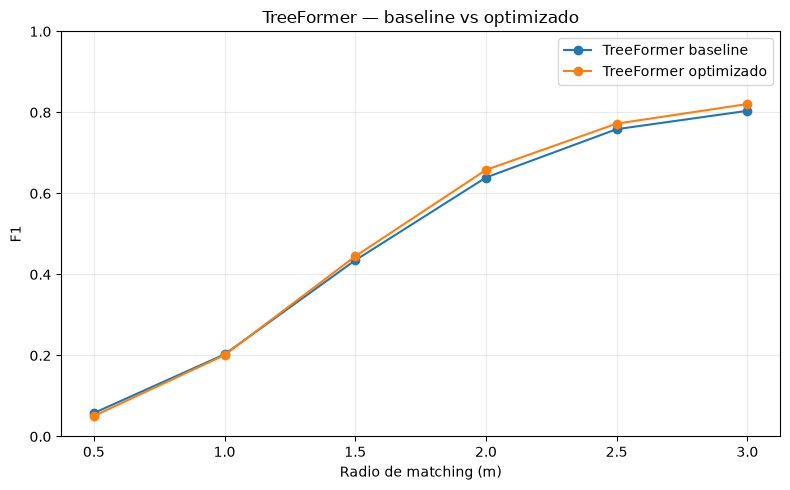

Gráfico guardado: G:\Mi unidad\Maestría Ciencia de Datos\Tesis\proyecto\Entrega\resultados\treeformer_uv\tuning\treeformer_baseline_vs_optimizado_f1.png


In [58]:
# Representar F1 frente al radio de matching.

baseline_curve = sensitivity_df.copy()
optimized_curve = optimized_sensitivity_df.copy()

plt.figure(figsize=(8, 5))

plt.plot(
    baseline_curve["match_radius_m"],
    baseline_curve["F1"],
    marker="o",
    label="TreeFormer baseline",
)

plt.plot(
    optimized_curve["match_radius_m"],
    optimized_curve["F1"],
    marker="o",
    label="TreeFormer optimizado",
)

plt.xlabel("Radio de matching (m)")
plt.ylabel("F1")
plt.title("TreeFormer — baseline vs optimizado")
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

curve_path = TUNING_DIR / "treeformer_baseline_vs_optimizado_f1.png"
plt.savefig(curve_path, dpi=200, bbox_inches="tight")
plt.show()

print("Gráfico guardado:", curve_path)